# HW4: Clean the class equity database

**Mauricio Gutierrez** · Input: `equities_class.duckdb`

This notebook adapts my HW2 cleaner to the database used in Lectures 7 and 8. It contains the complete workflow. The shared `data_cleaning.py` module contains the cleaning functions. The batch runner imports the same functions.

**Purpose:** produce usable price observations and dated financial reports, with a record of every excluded row and changed value. Keep the source database unchanged. Do not train a model or choose trades here.

```text
Source DuckDB (read only)
          |
          v
Table guide -> Raw tables -> Data-quality checks
                                  |
                    +-------------+-------------+
                    |             |             |
                    v             v             v
                Keep rows    Remove exact   Quarantine rows
                with flags    duplicates    with a reason
                    |             |             |
                    +-------------+-------------+
                                  |
                                  v
                      Validation + timing checks
                                  |
                                  v
                 Separate cleaned DuckDB + audit files
```

**Run:** select the course `.venv` kernel, then run the cells from top to bottom. The saved outputs describe the class database through December 31, 2015. Generated files go into this homework folder's ignored `outputs/` directory.

**Read:** start with Sections 1–3 for the data and decisions. Read `data_cleaning.py` to inspect the shared functions. Sections 9–12 show the results, tests, and saved files.

**Full database:** Run `clean_full_database.py` from the repository root. This runner imports the same cleaning functions. It saves one group of 50 complete stock histories at a time. Run the same command to resume an interrupted run. Do not change this notebook's class settings for that task.

```text
Notebook 01 (class data) ----+--> data_cleaning.py --> Checks and audit tables
Batch runner (full data) ---+
```


## 1. Understand the database

A DuckDB file holds several named tables. A row represents one observation. A **key** identifies that observation. For example, `(symbol, date)` identifies one stock on one trading date.

| Table | One row represents | Main use |
|---|---|---|
| `prices` | One stock on one market date | Prices, returns, and execution quotes. |
| `fundamentals` | One stock's fiscal period | Financial statement values and publication dates. |
| `universe` | One stored security | Name, sector, and source-snapshot metadata. |
| `universe_membership` | One stock selected for one quarter | Stocks eligible for new entries in that quarter. |
| `calendar` | One market session | Valid trading dates, including exchange holidays. |
| `benchmark` | One market date for `^SP500TR` | S&P 500 total-return comparison. |
| `universe_candidates` | One stock considered at a quarterly selection | Audit the original selection inputs. |
| `universe_rebalances` | One quarterly selection | Audit coverage and stock counts. |
| `dividends` | One recorded dividend event | Optional corporate-action research. Do not add these dividends to adjusted-price returns. |
| `dataset_metadata` | One metadata item | Identify the source dataset. |

```text
universe.symbol ---- prices.symbol + date ---------- calendar.date
       |                                                   |
       +----------- fundamentals.symbol + fiscal_date      +--- benchmark.date
       |
       +----------- universe_membership.symbol + quarter_start
```

`universe` is an inventory, not a list of stocks eligible on every past date. Keep inactive stocks and histories outside membership periods. A held stock still needs prices after it leaves the entry universe.

### Read the price columns

| Column | Meaning |
|---|---|
| `symbol` | Stock identifier. HW2 called this `ticker`. |
| `date` | Date of the observation. HW2 called this `ts`. |
| `open`, `high`, `low`, `close` | Supplied opening, highest, lowest, and closing prices for that session. |
| `adj_close` | Vendor-adjusted close. Use it consistently for the course's total-return exposure. |
| `volume` | Reported number of shares traded. Missing volume is not zero volume. |
| `source` | Vendor/source label. |

OHLC means **open, high, low, close**. Test `low <= open/close <= high` on those four columns. Do not compare `adj_close` with the OHLC bounds: it uses a different adjustment basis. Do not assume that a large price or a changing adjustment factor is an error.

### Read the financial dates

`fiscal_date` ends the reported accounting period. `filing_date` records publication. The source has no publication time, so use `available_date = filing_date + 1 calendar day`. Only use a report on or after `available_date`.

Values such as revenue, net income, assets, and cash flow use the vendor's reported units and currency. Negative income or equity can be valid. Missing currency is a limitation; this notebook does not assume USD or compare raw monetary amounts across companies.

## 2. Import packages and select the source

Use `duckdb` for database access, `pandas` for tables, and `numpy` for numeric checks. Use `matplotlib` for one review plot. All cleaning functions appear below.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
import hashlib
import io
import json

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

pd.set_option("display.max_rows", 12)
pd.set_option("display.max_columns", 10)


def find_repository(start):
    """Resolve paths from the notebook folder or repository root."""
    for parent in [Path(start).resolve(), *Path(start).resolve().parents]:
        for candidate in [parent, parent / "UCB-MFE-python-preprogram-2026-winter"]:
            if (candidate / "pyproject.toml").is_file() and (candidate / "Lectures/modeling").is_dir():
                return candidate
    raise FileNotFoundError("Start Jupyter inside the course repository or its workspace.")


REPO_ROOT = find_repository(Path.cwd())
HW4_DIR = REPO_ROOT / "Homeworks/HW4/Mauricio_Gutierrez"

import sys
sys.path.insert(0, str(HW4_DIR))
from data_cleaning import (
    RETURN_WINDOW,
    MIN_RETURN_HISTORY,
    OUTLIER_STD,
    LARGE_MOVE,
    FACTOR_CHANGE,
    file_sha256,
    normalize_symbol,
    ISSUE_COLUMNS,
    OHLC_COLUMNS,
    PRICE_COLUMNS,
    make_issues,
    concat_issues,
    prepare_rows,
    split_duplicates,
    split_invalid_rows,
    join_quarantine,
    row_accounting,
    clean_prices,
    add_past_only_price_flags,
    clean_fundamentals,
    latest_available_report,
    missing_value_summary,
    price_validation,
)

DB_PATH = REPO_ROOT / "Lectures/modeling/data/equities_class.duckdb"
LOAD_END = pd.Timestamp("2015-12-31")
SAVE_OUTPUTS = True
OUTPUT_DIR = HW4_DIR / "outputs/data_cleaning" / DB_PATH.stem
OUTPUT_DB = OUTPUT_DIR / f"{DB_PATH.stem}_cleaned.duckdb"

# These thresholds create review flags. They do not remove large returns.

if not DB_PATH.is_file():
    raise FileNotFoundError(f"Download {DB_PATH.name} from bCourses into {DB_PATH.parent}.")
if OUTPUT_DB.resolve() == DB_PATH.resolve():
    raise ValueError("The output database must differ from the source database.")




SOURCE_SHA256 = file_sha256(DB_PATH)
print("Source:", DB_PATH.name)
print("Last loaded date:", LOAD_END.date())
display(pd.Series({name: version(name) for name in ["duckdb", "pandas", "numpy", "matplotlib"]}, name="version").to_frame())

Source: equities_class.duckdb
Last loaded date: 2015-12-31


,version
duckdb,1.5.6
pandas,2.3.3
numpy,2.3.5
matplotlib,3.10.7


### Load six working tables

Read the source in **read-only mode**. Keep earlier history for lookbacks. Do not filter by current active status, future price coverage, or a stock's later performance.

For financial records, the load boundary uses the fiscal date. A report with a later publication date still needs its own availability check. Cleaning does not make that report available early.

The other source tables remain in the original database. This output is a working dataset with audits, not a complete copy of every source table. Use the full homework database later with bounded reads; this notebook currently targets the small class dataset.

In [2]:
TABLE_QUERIES = {
    "prices": "SELECT * FROM prices WHERE date <= ? ORDER BY symbol, date",
    "fundamentals": "SELECT * FROM fundamentals WHERE fiscal_date <= ? ORDER BY symbol, fiscal_date, period",
    "universe": "SELECT * FROM universe ORDER BY symbol",
    "universe_membership": "SELECT * FROM universe_membership WHERE quarter_start <= ? ORDER BY quarter_start, universe_rank",
    "benchmark": "SELECT * FROM benchmark WHERE date <= ? ORDER BY date",
    "calendar": "SELECT * FROM calendar WHERE date <= ? ORDER BY date",
}

with duckdb.connect(str(DB_PATH), read_only=True) as connection:
    available_tables = connection.execute("SHOW TABLES").fetchdf()
    missing_tables = set(TABLE_QUERIES) - set(available_tables["name"])
    if missing_tables:
        raise ValueError(f"Required tables are missing: {sorted(missing_tables)}")
    raw = {
        table: connection.execute(sql, [LOAD_END.date()] if "?" in sql else []).fetchdf()
        for table, sql in TABLE_QUERIES.items()
    }
    schema = connection.execute("""
        SELECT table_name, column_name, data_type
        FROM information_schema.columns
        WHERE table_schema = 'main'
        ORDER BY table_name, ordinal_position
    """).fetchdf()

raw_before = {name: frame.copy(deep=True) for name, frame in raw.items()}
table_summary = pd.DataFrame([
    {"table": name, "loaded_rows": len(frame), "columns": len(frame.columns)}
    for name, frame in raw.items()
])
display(table_summary)
display(raw["prices"].head(3))
display(raw["fundamentals"][["symbol", "fiscal_date", "filing_date", "net_income", "reported_currency"]].head(3))

,table,loaded_rows,columns
0,prices,59286,9
1,fundamentals,1059,46
2,universe,30,11
3,universe_membership,937,12
4,benchmark,2015,5
5,calendar,2015,1


,symbol,date,open,high,low,close,adj_close,volume,source
0,AAPL,2008-01-02,7.12,7.15,6.88,6.96,5.83,1079178800,fmp
1,AAPL,2008-01-03,6.98,7.05,6.88,6.96,5.83,842066568,fmp
2,AAPL,2008-01-04,6.84,6.89,6.39,6.43,5.39,1455832000,fmp


,symbol,fiscal_date,filing_date,net_income,reported_currency
0,AAPL,2007-03-31,2007-05-10,770000000.0,None
1,AAPL,2007-06-30,2007-08-08,818000000.0,None
2,AAPL,2007-09-29,2007-11-15,904000000.0,None


## 3. Set cleaning decisions before changing data

This adapts HW2's **inspect -> diagnose -> clean -> validate -> save** structure. It changes repairs that would be unsuitable for historical forecasts.

| Observation | Action | Reason |
|---|---|---|
| HTML, surrounding spaces, or case differences in a stock label | Normalize the label; retain `raw_symbol`. | Match a known security consistently. |
| Identical repeated record | Keep one copy; save removed copies separately. | Avoid counting one observation twice. |
| Conflicting records with the same key | Quarantine every distinct version. | There is no reliable rule to choose the true value. |
| Invalid key, unknown stock, off-calendar date, or unusable price | Quarantine the row with a reason. | Do not create a tradable quote. |
| Broken OHLC bounds | Quarantine the row. | Its supplied price range is inconsistent. |
| Missing volume | Keep it missing; flag the row. | Unknown trading volume is not zero. |
| Negative, infinite, or nonnumeric volume | Replace that value with missing; flag it. | Preserve usable prices without inventing volume. |
| Zero volume | Keep and flag. | Zero volume alone does not prove an error. |
| Missing market sessions | Report the gaps. | Do not forward-fill a price or bridge a gap with a daily return. |
| Large return or adjustment-factor change | Keep and flag using past data only. | A market move or corporate action can be real. |
| Missing filing date or filing date on/before fiscal end | Quarantine the financial report. | Its historical availability is not reliable. |
| Valid report | Add the next-calendar-day availability date. | Avoid assuming publication before that day's close. |
| Infinite/nonnumeric financial value | Replace that cell with missing; flag it. | Keep the other usable values in the report. |
| Missing financial value, unknown currency, or missing market cap | Preserve missingness; report the limitation. | Do not invent fundamentals or currencies. |
| Negative income, cash flow, or equity | Keep it. | These values can describe a real loss or balance sheet. |

**Quarantine** means exclude a row from the cleaned working table and save it with a reason. It does not mean delete the source row.

HW2 used the next day's price to detect and interpolate some round trips. This notebook does not use that repair. It also does not rebuild adjusted close from an HW2 reference table, because that reference is not present here.

An issue report can contain several issues for one row. The row-accounting table counts each input row exactly once.

## 4. Validate the calendar and reference tables

The calendar, benchmark, security inventory, and membership dates control later checks. Stop if their essential relationships fail. Do not silently repair an uncertain reference date.

Source sector labels and active-status fields describe the vendor snapshot. Keep them as metadata. Do not treat active status or future membership counts as historical model inputs.

In [3]:
calendar = pd.DatetimeIndex(raw["calendar"]["date"])
universe = raw["universe"].copy()
membership = raw["universe_membership"].copy()
benchmark = raw["benchmark"].copy()
known_symbols = set(universe["symbol"])

reference_checks = pd.Series({
    "calendar is nonempty, unique, and ordered": len(calendar) > 0 and calendar.is_unique and calendar.is_monotonic_increasing,
    "calendar has no missing dates": not calendar.hasnans,
    "universe symbols are unique and present": universe["symbol"].notna().all() and not universe["symbol"].duplicated().any(),
    "universe symbols already use canonical labels": normalize_symbol(universe["symbol"]).eq(universe["symbol"]).all(),
    "benchmark has one row per session": pd.DatetimeIndex(benchmark["date"]).equals(calendar),
    "benchmark is SP500 total return": benchmark["symbol"].eq("^SP500TR").all(),
    "benchmark adjusted closes are positive and finite": (np.isfinite(benchmark["adj_close"]) & benchmark["adj_close"].gt(0)).all(),
    "membership keys are unique": not membership.duplicated(["symbol", "quarter_start"]).any(),
    "membership uses known stocks": membership["symbol"].isin(known_symbols).all(),
    "membership dates are present": membership[["quarter_start", "quarter_end", "selection_date", "effective_start"]].notna().all().all(),
    "selection precedes the effective entry date": membership["selection_date"].lt(membership["effective_start"]).all(),
    "effective entry belongs to its quarter": (membership["effective_start"].ge(membership["quarter_start"]) & membership["effective_start"].le(membership["quarter_end"])).all(),
    "selection uses already available shares": membership["shares_available_date"].le(membership["selection_date"]).all(),
    "supplied ranks are valid": membership["universe_rank"].between(1, 2000).all(),
}, name="passed")
with pd.option_context("display.max_rows", None):
    display(reference_checks.to_frame())
if not reference_checks.all():
    raise ValueError("Investigate the failed reference checks before cleaning prices.")

,passed
"calendar is nonempty, unique, and ordered",True
calendar has no missing dates,True
universe symbols are unique and present,True
universe symbols already use canonical labels,True
benchmark has one row per session,True
benchmark is SP500 total return,True
benchmark adjusted closes are positive and finite,True
membership keys are unique,True
membership uses known stocks,True
membership dates are present,True


## 5. Build reusable audit functions

Each issue has a source table, source row number, stock, date, issue type, severity, action, and explanation. `source_row` is a zero-based position in the loaded table. It is an audit identifier, not a model feature.

Severity describes the action needed: **high** means an unusable observation; **medium** means a limitation or value to inspect; **low** means a review item. A low-severity flag is not proof that a value is correct.

In [4]:
# The shared data_cleaning module supplies this function.

## 6. Clean price observations

Keep a price row only when its key is valid, its date belongs to the supplied calendar, its stock is known, and its prices are positive, finite, and internally consistent. Report all excluded rows.

Preserve missing volume. Convert invalid volume to missing with a flag. This allows usable prices to remain available without claiming that unknown volume is zero.

This function does not remove large returns. The next step adds review flags after the price keys are unique.

In [5]:
prices_cleaned, prices_quarantine, prices_duplicates, price_issues, price_account = clean_prices(
    raw["prices"], calendar, known_symbols
)
display(pd.DataFrame([price_account]))
display(prices_quarantine[["source_row", "symbol", "date", "quarantine_reason"]].head(8))

,table,raw_rows,kept_rows,duplicate_rows,quarantined_rows
0,prices,59286,59286,0,0


,source_row,symbol,date,quarantine_reason


### Find gaps and flag unusual returns

Put each stock on the shared market calendar before calculating daily returns. Leave an absent quote missing. The first quote after a gap must not produce a multi-session return labeled as a daily return.

Compare today's return with the preceding 63 market sessions. Require at least 20 observed prior returns. Shift the reference mean and standard deviation by one session, so today's return does not set its own threshold. Keep every flagged price unchanged.

The missing-session report covers the span from each stock's first to last usable quote. It is a retrospective coverage audit. It does not establish a listing date, a delisting date, a cash recovery, or historical eligibility. Check held-stock gaps separately in the backtester.

In [6]:
prices_cleaned, missing_sessions = add_past_only_price_flags(prices_cleaned, calendar)
flag_issues = []
for flag, explanation in {
    "flag_return_outlier": "Return exceeds the prior-data standard-deviation threshold; price retained.",
    "flag_large_move": "Absolute daily return exceeds 30%; price retained for investigation.",
    "flag_factor_change": "Adjustment factor changed by more than the configured multiple; may be a corporate action.",
    "flag_gap_before_quote": "Prior market-session quote is missing; daily return remains missing.",
}.items():
    flag_issues.append(make_issues(prices_cleaned.loc[prices_cleaned[flag]], "prices", "date", flag.removeprefix("flag_"), explanation, "medium", "keep_flagged"))
if not missing_sessions.empty:
    gap_rows = missing_sessions.assign(source_row=pd.NA)
    flag_issues.append(make_issues(gap_rows, "prices", "date", "missing_usable_quote", "No usable quote inside the observed span; no price inserted.", "medium", "report_gap"))
price_issues = concat_issues([price_issues, *flag_issues])
display(prices_cleaned.filter(like="flag_").sum().rename("flagged_rows").to_frame())
display(missing_sessions.groupby("symbol").size().rename("missing_sessions").to_frame())

,flagged_rows
flag_symbol_normalized,0
flag_volume_invalid,0
flag_volume_missing,0
flag_zero_volume,2401
flag_return_outlier,921
flag_large_move,102
flag_factor_change,4
flag_gap_before_quote,370


,missing_sessions
symbol,
CCZ,1158


## 7. Clean financial reports and add availability dates

Keep the financial report as an event. Do not join it to earlier prices here. Remove exact copies and quarantine conflicting keys, unknown stocks, invalid fiscal dates, unsupported periods, and missing or nonpositive filing lags.

For valid quarterly reports, calculate `available_date`. Keep unknown currency and missing market capitalization visible. Do not substitute zero for a missing amount. Do not remove a report merely because net income is negative.

The source stores latest vendor values, not original filing versions. Date checks cannot undo later restatements. Downstream feature code must also handle late filings for older periods and stale reports.

In [7]:
financial_numeric_columns = schema.loc[
    schema["table_name"].eq("fundamentals")
    & schema["data_type"].str.contains(r"DOUBLE|FLOAT|DECIMAL|INTEGER|BIGINT|SMALLINT", regex=True),
    "column_name",
].tolist()




fundamentals_cleaned, fundamentals_quarantine, fundamentals_duplicates, fundamental_issues, fundamental_account = clean_fundamentals(
    raw["fundamentals"], known_symbols, financial_numeric_columns
)
display(pd.DataFrame([fundamental_account]))
display(fundamentals_quarantine[["symbol", "fiscal_date", "filing_date", "quarantine_reason"]].head(8))
display(fundamentals_cleaned[["symbol", "fiscal_date", "filing_date", "available_date"]].head(5))

,table,raw_rows,kept_rows,duplicate_rows,quarantined_rows
0,fundamentals,1059,1045,0,14


,symbol,fiscal_date,filing_date,quarantine_reason
0,GE,2014-06-30,2014-06-30,invalid_filing_lag
1,GE,2014-09-30,2014-09-30,invalid_filing_lag
2,GE,2014-12-31,2014-12-31,invalid_filing_lag
3,IBM,2014-03-31,2014-03-31,invalid_filing_lag
4,T,2007-12-31,2007-12-31,invalid_filing_lag
5,T,2008-03-31,2008-03-31,invalid_filing_lag
6,T,2008-09-30,2008-09-30,invalid_filing_lag
7,T,2008-12-31,2008-12-31,invalid_filing_lag


,symbol,fiscal_date,filing_date,available_date
0,AAPL,2007-03-31,2007-05-10,2007-05-11
1,AAPL,2007-06-30,2007-08-08,2007-08-09
2,AAPL,2007-09-29,2007-11-15,2007-11-16
3,AAPL,2007-12-29,2008-02-01,2008-02-02
4,AAPL,2008-03-29,2008-05-01,2008-05-02


## 8. Check what financial information was available

This example selects the latest fiscal period already published by one signal date. An old period filed late must not replace a newer fiscal period already known. A fiscal period more than 550 calendar days old is treated as stale in the course examples.

This is an availability demonstration, not feature engineering. A filing-day report is excluded until the following calendar day. Historical prices at the signal close can support a decision for the next session's close.

In [8]:
availability_examples = []
for signal_date in ["2014-01-28", "2014-01-29"]:
    report = latest_available_report(fundamentals_cleaned, "AAPL", signal_date)
    if not report.empty:
        availability_examples.append(report[["symbol", "fiscal_date", "filing_date", "available_date"]].assign(signal_date=signal_date))
display(pd.concat(availability_examples, ignore_index=True) if availability_examples else pd.DataFrame())

,symbol,fiscal_date,filing_date,available_date,signal_date
0,AAPL,2013-09-28,2013-10-30,2013-10-31,2014-01-28
1,AAPL,2013-12-28,2014-01-28,2014-01-29,2014-01-29


## 9. Read the combined quality report

Separate three quantities:

1. **Row accounting:** where each input row went.
2. **Issue counts:** how many observations triggered each check. One row can trigger several checks.
3. **Missing cells and sessions:** what remains unknown. Cleaning does not make unknown data complete.

The tables below are calculated from the current run. They are not hard-coded expected results.

In [9]:
quality_report = concat_issues([price_issues, fundamental_issues])
quality_report["source_row"] = pd.to_numeric(quality_report["source_row"], errors="coerce").astype("Int64")
quality_report["issue_date"] = pd.to_datetime(quality_report["issue_date"], errors="coerce")
quality_report = quality_report.sort_values(["source_table", "symbol", "issue_date", "issue_type"], na_position="last").reset_index(drop=True)

accounting = pd.DataFrame([price_account, fundamental_account])
accounting["reconciles"] = accounting["raw_rows"].eq(accounting[["kept_rows", "duplicate_rows", "quarantined_rows"]].sum(axis=1))
quality_summary = quality_report.groupby(["source_table", "issue_type", "action"], dropna=False).size().rename("issues").reset_index()



missing_values = pd.concat([
    missing_value_summary(raw["prices"], prices_cleaned, "prices"),
    missing_value_summary(raw["fundamentals"], fundamentals_cleaned, "fundamentals"),
], ignore_index=True)

display(accounting)
display(quality_summary)
display(missing_values.loc[missing_values[["missing_before", "missing_after"]].gt(0).any(axis=1)])
display(quality_report.head(10))

print(f"Kept {len(prices_cleaned):,} price rows and {len(fundamentals_cleaned):,} financial reports.")
print(f"Quarantined {len(prices_quarantine):,} price rows and {len(fundamentals_quarantine):,} financial reports.")
print(f"Reported {len(missing_sessions):,} missing usable quotes inside observed stock histories.")
print("Issue counts can overlap. Use row accounting to reconcile source records.")

Kept 59,286 price rows and 1,045 financial reports.
Quarantined 0 price rows and 14 financial reports.
Reported 1,158 missing usable quotes inside observed stock histories.
Issue counts can overlap. Use row accounting to reconcile source records.


,table,raw_rows,kept_rows,duplicate_rows,quarantined_rows,reconciles
0,prices,59286,59286,0,0,True
1,fundamentals,1059,1045,0,14,True


,source_table,issue_type,action,issues
0,fundamentals,currency_unknown,keep_missing,1044
1,fundamentals,invalid_filing_lag,quarantine,14
2,fundamentals,market_cap_missing,keep_missing,967
3,prices,factor_change,keep_flagged,4
4,prices,gap_before_quote,keep_flagged,370
5,prices,large_move,keep_flagged,102
6,prices,missing_usable_quote,report_gap,1158
7,prices,return_outlier,keep_flagged,921
8,prices,zero_volume,keep_flagged,2401


,table,column,missing_before,missing_after
14,fundamentals,gross_profit,1,1
15,fundamentals,operating_income,1,1
17,fundamentals,ebitda,1,1
18,fundamentals,eps,1,1
19,fundamentals,eps_diluted,1059,1045
...,...,...,...,...
50,fundamentals,long_term_debt,9,9
51,fundamentals,goodwill_and_intangibles,9,9
52,fundamentals,reported_currency,1058,1044
53,fundamentals,period_start,1058,1044


,source_table,source_row,symbol,issue_date,issue_type,severity,action,description
0,fundamentals,0,AAPL,2007-03-31,currency_unknown,medium,keep_missing,Reported currency is unknown; do not assume US...
1,fundamentals,1,AAPL,2007-06-30,currency_unknown,medium,keep_missing,Reported currency is unknown; do not assume US...
2,fundamentals,2,AAPL,2007-09-29,currency_unknown,medium,keep_missing,Reported currency is unknown; do not assume US...
3,fundamentals,3,AAPL,2007-12-29,currency_unknown,medium,keep_missing,Reported currency is unknown; do not assume US...
4,fundamentals,4,AAPL,2008-03-29,currency_unknown,medium,keep_missing,Reported currency is unknown; do not assume US...
5,fundamentals,5,AAPL,2008-06-28,currency_unknown,medium,keep_missing,Reported currency is unknown; do not assume US...
6,fundamentals,6,AAPL,2008-09-27,currency_unknown,medium,keep_missing,Reported currency is unknown; do not assume US...
7,fundamentals,7,AAPL,2008-12-27,currency_unknown,medium,keep_missing,Reported currency is unknown; do not assume US...
8,fundamentals,8,AAPL,2009-03-28,currency_unknown,medium,keep_missing,Reported currency is unknown; do not assume US...
9,fundamentals,9,AAPL,2009-06-27,currency_unknown,medium,keep_missing,Reported currency is unknown; do not assume US...


### Inspect a flagged return

The plot shows actual retained prices and a daily-return review flag. A flag starts an investigation. It does not justify replacing the price with a smooth value.

For the class dataset, AAPL provides a readable example. Adjust `REVIEW_SYMBOL` when investigating another stock. The return thresholds use only earlier observations, even though the chart shows the full review interval.

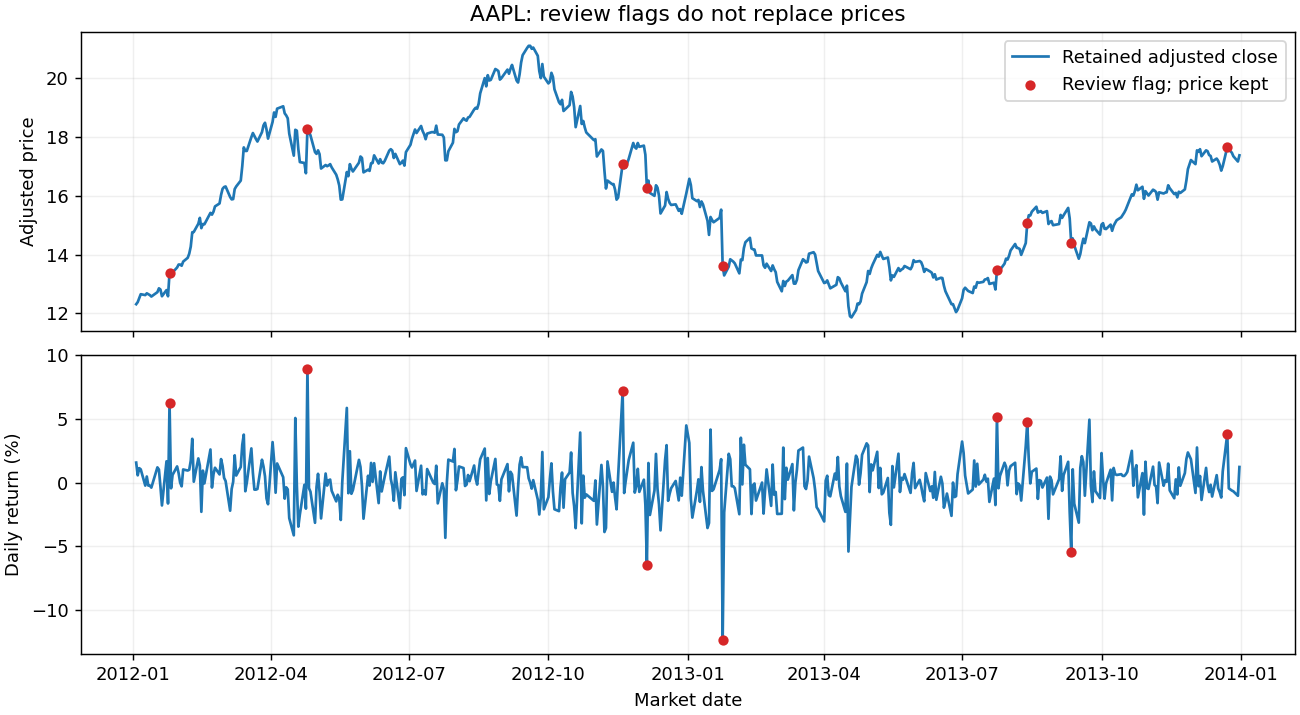

In [10]:
REVIEW_SYMBOL = "AAPL"
review = prices_cleaned.loc[
    prices_cleaned["symbol"].eq(REVIEW_SYMBOL)
    & prices_cleaned["date"].between("2012-01-01", "2013-12-31")
].copy()
plot_bytes = None
if not review.empty:
    flagged = review["flag_return_outlier"] | review["flag_large_move"]
    figure, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, layout="constrained")
    axes[0].plot(review["date"], review["adj_close"], label="Retained adjusted close")
    axes[0].scatter(review.loc[flagged, "date"], review.loc[flagged, "adj_close"], s=22, color="tab:red", label="Review flag; price kept", zorder=3)
    axes[0].set_ylabel("Adjusted price")
    axes[0].set_title(f"{REVIEW_SYMBOL}: review flags do not replace prices")
    axes[0].legend(loc="best")
    axes[1].plot(review["date"], review["daily_return"] * 100, label="Observed daily return")
    axes[1].scatter(review.loc[flagged, "date"], review.loc[flagged, "daily_return"] * 100, s=22, color="tab:red", zorder=3)
    axes[1].set_ylabel("Daily return (%)")
    axes[1].set_xlabel("Market date")
    for axis in axes:
        axis.grid(alpha=0.2)
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", dpi=130)
    plot_bytes = buffer.getvalue()
    display(Image(data=plot_bytes))
    plt.close(figure)
else:
    print("No observations in the chosen plot interval.")

## 10. Validate cleaned tables

Check the properties that later code needs. Missing volume and missing financial amounts are allowed and documented. Missing or invalid execution prices are not filled.

Use the row accounting to prove that all source records have a destination. Compare the raw in-memory tables and the source file hash with their original values. Keep existing stocks regardless of current active status.

Passing these checks does not certify every vendor value as economically correct. It proves the listed structural checks and timing rules.

In [11]:
validation_results = price_validation(prices_cleaned, calendar, known_symbols)
original_prices = raw["prices"].iloc[prices_cleaned["source_row"].to_numpy()][PRICE_COLUMNS].to_numpy(dtype=float)
validation_results["prices: retained observed prices are unchanged"] = np.array_equal(
    prices_cleaned[PRICE_COLUMNS].to_numpy(dtype=float), original_prices, equal_nan=True
)
validation_results.update({
    "financials: unique report keys": not fundamentals_cleaned.duplicated(["symbol", "fiscal_date", "period"]).any(),
    "financials: quarterly reports": fundamentals_cleaned["period"].eq("quarter").all(),
    "financials: valid known stocks": fundamentals_cleaned["symbol"].isin(known_symbols).all(),
    "financials: publication follows fiscal end": fundamentals_cleaned["filing_date"].gt(fundamentals_cleaned["fiscal_date"]).all(),
    "financials: next-day availability": fundamentals_cleaned["available_date"].eq(fundamentals_cleaned["filing_date"] + pd.Timedelta(days=1)).all(),
    "financials: numeric values are finite or missing": all((fundamentals_cleaned[col].isna() | np.isfinite(fundamentals_cleaned[col])).all() for col in financial_numeric_columns),
    "accounting: every source row has one destination": accounting["reconciles"].all(),
    "scope: no prices beyond the load boundary": prices_cleaned["date"].le(LOAD_END).all(),
    "source: database file is unchanged": file_sha256(DB_PATH) == SOURCE_SHA256,
})
for name, original in raw_before.items():
    pd.testing.assert_frame_equal(raw[name], original)
validation_results["source: all raw in-memory tables are unchanged"] = True
validation_results["universe: inactive securities were retained"] = universe.equals(raw["universe"])

validation = pd.Series(validation_results, name="passed").rename_axis("check").reset_index()
with pd.option_context("display.max_rows", None):
    display(validation)
if not validation["passed"].all():
    raise AssertionError("Do not export. Investigate the failed validation checks.")

,check,passed
0,prices: one row per symbol/date,True
1,prices: valid known keys,True
2,prices: positive finite prices,True
3,prices: valid OHLC bounds,True
4,prices: dates are market sessions,True
5,prices: volume is missing or nonnegative and f...,True
6,prices: no daily returns across a missing quote,True
7,prices: daily returns are missing or finite,True
8,prices: retained observed prices are unchanged,True
9,financials: unique report keys,True


## 11. Test repairs and historical timing with small examples

The class price table does not contain every type of error. Inject known errors into a tiny synthetic table to test those branches.

The expected behavior is explicit:

- Remove one exact duplicate.
- Quarantine both conflicting records.
- Quarantine unusable prices and invalid dates.
- Replace negative volume with missing.
- Keep missing sessions and missing volume visible.
- Keep a large but structurally valid price move.
- Leave past values and flags unchanged when future prices change.

The synthetic calendar contains weekdays for this test only. Real data always uses the supplied exchange calendar.

In [12]:
demo_calendar = pd.bdate_range("2013-01-02", periods=45)
levels = 100 + np.arange(45) * 0.1 + np.sin(np.arange(45)) * 0.5
demo = pd.DataFrame({
    "symbol": "DEMO", "date": demo_calendar, "open": levels, "high": levels + 1,
    "low": levels - 1, "close": levels, "adj_close": levels, "volume": 1000.0, "source": "synthetic",
})
demo.loc[2, "symbol"] = '<span>demo</span>'
demo.loc[4, "volume"] = -5
demo.loc[5, "adj_close"] = 0
demo.loc[6, "low"] = demo.loc[6, "high"] + 1
demo.loc[7, "adj_close"] = np.nan
demo.loc[8, "volume"] = np.nan
demo.loc[35, PRICE_COLUMNS] *= 2
demo = demo.drop(index=10)
duplicate = demo.loc[[3]].copy()
conflict = demo.loc[[12]].copy()
conflict[PRICE_COLUMNS] *= 1.02
invalid_date = demo.iloc[[0]].copy().assign(date=pd.NaT)
off_calendar = demo.iloc[[0]].copy().assign(date=pd.Timestamp("2013-01-05"))
demo = pd.concat([demo, duplicate, conflict, invalid_date, off_calendar], ignore_index=True)
demo_before = demo.copy(deep=True)

demo_clean, demo_quarantine, demo_duplicates, demo_issues, demo_account = clean_prices(demo, demo_calendar, {"DEMO"})
demo_clean, demo_gaps = add_past_only_price_flags(demo_clean, demo_calendar)
assert len(demo_duplicates) == 1
assert demo_quarantine["quarantine_reason"].eq("conflicting key").sum() == 2
assert demo_clean.loc[demo_clean["date"].eq(demo_calendar[4]), "volume"].isna().all()
assert demo_clean.loc[demo_clean["date"].eq(demo_calendar[8]), "volume"].isna().all()
assert not demo_clean["date"].eq(demo_calendar[10]).any()
assert demo_clean.loc[demo_clean["date"].eq(demo_calendar[11]), "daily_return"].isna().all()
assert demo_clean.loc[demo_clean["date"].eq(demo_calendar[35]), "flag_large_move"].all()
assert demo_clean.loc[demo_clean["date"].eq(demo_calendar[35]), "adj_close"].iloc[0] == levels[35] * 2
assert all(price_validation(demo_clean, demo_calendar, {"DEMO"}).values())
pd.testing.assert_frame_equal(demo, demo_before)

# Change only future prices. Earlier clean values and review flags must stay identical.
cutoff = demo_calendar[32]
changed_future = demo.copy(deep=True)
changed_future.loc[changed_future["date"].gt(cutoff), PRICE_COLUMNS] *= 4
changed_clean, *_ = clean_prices(changed_future, demo_calendar, {"DEMO"})
changed_clean, _ = add_past_only_price_flags(changed_clean, demo_calendar)
prefix_raw = demo.loc[demo["date"].le(cutoff)].copy()
prefix_clean, *_ = clean_prices(prefix_raw, demo_calendar[demo_calendar <= cutoff], {"DEMO"})
prefix_clean, _ = add_past_only_price_flags(prefix_clean, demo_calendar[demo_calendar <= cutoff])
causal_columns = ["symbol", "date", *PRICE_COLUMNS, "daily_return", "prior_return_zscore", "flag_return_outlier", "flag_large_move", "flag_factor_change", "flag_gap_before_quote"]
expected_prefix = demo_clean.loc[demo_clean["date"].le(cutoff), causal_columns].reset_index(drop=True)
pd.testing.assert_frame_equal(expected_prefix, changed_clean.loc[changed_clean["date"].le(cutoff), causal_columns].reset_index(drop=True))
pd.testing.assert_frame_equal(expected_prefix, prefix_clean[causal_columns].reset_index(drop=True))

display(pd.DataFrame([demo_account]))
display(demo_quarantine[["date", "quarantine_reason"]])
print("Price repair, gap handling, raw-data preservation, and future-data independence checks passed.")

Price repair, gap handling, raw-data preservation, and future-data independence checks passed.


,table,raw_rows,kept_rows,duplicate_rows,quarantined_rows
0,prices,48,40,1,7


,date,quarantine_reason
0,2013-01-18,conflicting key
1,2013-01-18,conflicting key
2,2013-01-09,unusable_price
3,2013-01-10,ohlc_bounds
4,2013-01-11,unusable_price
5,NaT,invalid_date
6,2013-01-05,off_calendar_date


### Test publication dates and negative earnings

Use a second small table to check financial reports. A loss must remain a loss. A report without reliable publication timing must not enter the working financial table. A late old report must not replace a newer period already available.

In [13]:
demo_financial = raw["fundamentals"].head(6).copy().reset_index(drop=True)
demo_financial["symbol"] = "DEMO"
demo_financial["fiscal_date"] = pd.to_datetime(["2011-03-31", "2011-06-30", "2011-09-30", "2011-12-31", "2012-03-31", "2012-06-30"])
demo_financial["filing_date"] = demo_financial["fiscal_date"] + pd.Timedelta(days=30)
demo_financial.loc[1, "filing_date"] = pd.NaT
demo_financial.loc[2, "filing_date"] = demo_financial.loc[2, "fiscal_date"]
demo_financial.loc[3, "net_income"] = -123.0
demo_financial.loc[4, "revenue"] = np.inf
financial_conflict = demo_financial.loc[[5]].copy()
financial_conflict["net_income"] += 1
demo_financial = pd.concat([demo_financial, demo_financial.loc[[0]], financial_conflict], ignore_index=True)
demo_financial_before = demo_financial.copy(deep=True)
demo_reports, demo_report_quarantine, demo_report_duplicates, _, demo_report_account = clean_fundamentals(
    demo_financial, {"DEMO"}, financial_numeric_columns
)
assert demo_report_account["raw_rows"] == 8
assert len(demo_reports) == 3 and len(demo_report_quarantine) == 4 and len(demo_report_duplicates) == 1
assert demo_reports.loc[demo_reports["fiscal_date"].eq(pd.Timestamp("2011-12-31")), "net_income"].iloc[0] == -123
assert demo_reports.loc[demo_reports["fiscal_date"].eq(pd.Timestamp("2012-03-31")), "revenue"].isna().all()
assert latest_available_report(demo_reports, "DEMO", "2011-04-30").empty
assert len(latest_available_report(demo_reports, "DEMO", "2011-05-01")) == 1

late_old = demo_reports.iloc[[0]].copy().assign(available_date=pd.Timestamp("2012-03-01"), filing_date=pd.Timestamp("2012-02-29"))
with_late_old = pd.concat([demo_reports, late_old], ignore_index=True)
assert latest_available_report(with_late_old, "DEMO", "2012-03-02")["fiscal_date"].iloc[0] == pd.Timestamp("2011-12-31")
pd.testing.assert_frame_equal(demo_financial, demo_financial_before)
display(pd.DataFrame([demo_report_account]))
print("Financial quarantine, negative earnings, availability, and late-filing checks passed.")

Financial quarantine, negative earnings, availability, and late-filing checks passed.


,table,raw_rows,kept_rows,duplicate_rows,quarantined_rows
0,fundamentals,8,3,1,4


## 12. Save a separate working database and audit files

Only export after validation and the small tests pass. The output directory is ignored by Git. Keep the notebook and README in the submission; regenerate large files locally.

| Output | Contents |
|---|---|
| `equities_class_cleaned.duckdb` | Six working tables plus quarantine, duplicate, quality-report, accounting, and validation tables. |
| `quality_report.csv` | Every reported issue and its action. |
| `quality_summary.csv` | Issue counts by table, type, and action. |
| `row_accounting.csv` | Kept, duplicate, and quarantine counts. |
| `missing_sessions.csv` | Unfilled session gaps inside observed histories. |
| `missing_values.csv` | Missing source cells before and after cleaning. |
| `validation.csv` | Validation results. |
| `source_schema.csv` | Original table names, column names, and database types. |
| `run_manifest.json` | Source filename and checksum, load boundary, parameters, versions, and output counts. |
| `price_review.png` | The retained-price review plot. |

In the new database, `prices` and `fundamentals` contain the cleaned rows. Their original column names remain usable by the lecture loaders. Extra audit columns are not automatically model features. Other provenance tables remain in the source database.

Rerunning this section replaces only these generated output tables and reports. It never writes to the source database.

In [14]:
tables_to_save = {
    "prices": prices_cleaned,
    "prices_quarantine": prices_quarantine,
    "prices_duplicates": prices_duplicates,
    "fundamentals": fundamentals_cleaned,
    "fundamentals_quarantine": fundamentals_quarantine,
    "fundamentals_duplicates": fundamentals_duplicates,
    "universe": universe,
    "universe_membership": membership,
    "benchmark": benchmark,
    "calendar": raw["calendar"],
    "quality_report": quality_report,
    "quality_summary": quality_summary,
    "row_accounting": accounting,
    "missing_sessions": missing_sessions,
    "validation": validation,
}
run_manifest = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "source_file": DB_PATH.name,
    "source_sha256": SOURCE_SHA256,
    "load_end": str(LOAD_END.date()),
    "return_window_sessions": RETURN_WINDOW,
    "minimum_prior_returns": MIN_RETURN_HISTORY,
    "return_std_threshold": OUTLIER_STD,
    "large_return_threshold": LARGE_MOVE,
    "factor_change_multiple": FACTOR_CHANGE,
    "financial_availability": "filing_date + 1 calendar day",
    "synthetic_checks_passed": True,
    "versions": {name: version(name) for name in ["duckdb", "pandas", "numpy", "matplotlib"]},
    "output_rows": {name: len(frame) for name, frame in tables_to_save.items()},
}

if SAVE_OUTPUTS:
    assert OUTPUT_DB.resolve() != DB_PATH.resolve()
    assert validation["passed"].all()
    assert file_sha256(DB_PATH) == SOURCE_SHA256
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    with duckdb.connect(str(OUTPUT_DB)) as connection:
        connection.execute("BEGIN TRANSACTION")
        try:
            for table_name, frame in tables_to_save.items():
                # Table names come from this fixed dictionary, not from input text.
                connection.register("cleaning_frame", frame)
                connection.execute(f'CREATE OR REPLACE TABLE "{table_name}" AS SELECT * FROM cleaning_frame')
                connection.unregister("cleaning_frame")
            connection.execute("COMMIT")
        except Exception:
            connection.execute("ROLLBACK")
            raise
    for filename, frame in {
        "quality_report": quality_report, "quality_summary": quality_summary,
        "row_accounting": accounting, "missing_sessions": missing_sessions,
        "missing_values": missing_values, "validation": validation, "source_schema": schema,
    }.items():
        frame.to_csv(OUTPUT_DIR / f"{filename}.csv", index=False, date_format="%Y-%m-%d")
    if plot_bytes is not None:
        (OUTPUT_DIR / "price_review.png").write_bytes(plot_bytes)
    (OUTPUT_DIR / "run_manifest.json").write_text(json.dumps(run_manifest, indent=2), encoding="utf-8")
    with duckdb.connect(str(OUTPUT_DB), read_only=True) as connection:
        saved_counts = {name: connection.execute(f'SELECT COUNT(*) FROM "{name}"').fetchone()[0] for name in tables_to_save}
    assert saved_counts == run_manifest["output_rows"]
    assert file_sha256(DB_PATH) == SOURCE_SHA256
    print("Saved and checked:", OUTPUT_DB.relative_to(REPO_ROOT))
    display(pd.Series(saved_counts, name="saved_rows").to_frame())
else:
    print("SAVE_OUTPUTS is False. Cleaned tables and audit reports remain in memory.")

Saved and checked: Homeworks\HW4\Mauricio_Gutierrez\outputs\data_cleaning\equities_class\equities_class_cleaned.duckdb


,saved_rows
prices,59286
prices_quarantine,0
prices_duplicates,0
fundamentals,1045
fundamentals_quarantine,14
...,...
quality_report,6981
quality_summary,9
row_accounting,2
missing_sessions,1158


## 13. Use the result in the next stage

1. Read `prices` from the cleaned database.
2. Reindex each stock to the supplied calendar before calculating rolling features.
3. Keep missing prices missing.
4. Select financial reports by `available_date` and the latest known fiscal period.
5. Apply quarterly membership to the intended entry date.
6. Build future-return targets separately from feature inputs.
7. Fit only on targets whose holding periods already ended.

Keep audit fields such as `source_row`, `raw_symbol`, `raw_date`, and `quarantine_reason` out of the feature list. Do not use current active status, full-history membership counts, or future target availability to decide which stocks existed at an earlier date.

### Limits that cleaning does not resolve

- Missing prices may prevent reliable execution or valuation of a held stock. Do not infer a payout, zero recovery, or an executable exit from a last observed row.
- Financial values may include later vendor restatements. Correct publication dates do not recover original filing versions.
- Most class financial rows have unknown currency. Units and currencies still need review before using monetary features.
- Sector labels are source snapshots. They can differ from historical classifications.
- The class database contains 30 teaching stocks. It is not the full homework evaluation universe.
- A review flag is not proof of a data error. Large valid market moves remain in the cleaned table.

### Sources and adaptation

- [My HW2 cleaner](../../HW2/Mauricio_Gutierrez/01_data_cleaning.ipynb): issue-report format, label normalization, duplicate handling, quarantine, and row reconciliation.
- [Course data guide](../../../Lectures/modeling/README.md): table meanings, availability timing, calendar rules, and source limitations.
- [Course data helpers](../../../Lectures/modeling/course_data.py): reference conventions for missing prices and report availability.
- [HW4 assignment](../../../Lectures/Lecture%208/hw4.md): holding-period and evaluation requirements.

Codex helped adapt and document this notebook. All cleaning code is included here. The model, allocation rules, and backtester remain separate later steps.